# One-branch vs two-branch MoE: re-evaluation and comparison
Re-evaluate the saved checkpoint of every phase on the test split (one-vs-rest macro F1), with the
same normal-traffic protocol as training (normal windows only from the recordings seen so far), and
draw the report charts. Both runs: Impala, phase order `variant`, reservoir memory 10k, seed 42,
decision rule `cls`; only the architecture differs.

| Label | Run | Architecture |
|---|---|---|
| One-branch MoE (ID-routed) | `save/ablation_final/impala/std_moe_s42` | router and experts read node features + CAN-ID embedding |
| Two-branch MoE (behavior) | `save/memory/impala/mem_reservoir_10k` | identity branch + behavior experts without ID, null expert |


In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.insert(0, str(Path('../').resolve()))
print(sys.path[:3])

['/home/hieutt/MoE-IVN-IDS', '/home/hieutt/MoE-IVN-IDS/notebooks', '/home/hieutt/miniconda3/envs/torchtf/lib/python39.zip']


In [2]:
# ============ CONFIG ============
GPU = 0
BATCH_SIZE = 256
RECOMPUTE = True          # the old cache was made with another data dir and protocol: recompute once

RUNS = [
    {"name": "One-branch MoE (ID-routed)", "arch": "cosine", "short": "cosine",
     "dir": "../save/ablation_final/impala/std_moe_s42",
     "data_dir": "../data/2011-chevrolet-impala/preprocessed_window"},   # the data it was trained on
    {"name": "Two-branch MoE (behavior)", "arch": "behavior", "short": "behavior",
     "dir": "../save/memory/impala/mem_reservoir_10k",
     "data_dir": "../data/2011-chevrolet-impala/preprocessed_window"},
]
NAME = {r["short"]: r["name"] for r in RUNS}
SHORT_LABEL = {"cosine": "One-branch", "behavior": "Two-branch"}
# Chart style
COLORS = {"behavior": "#D62728", "cosine": "#7F7F7F"}
PHASE_LABELS = ["P1\n(base 6)", "P2\n(+speed)", "P3\n(DoS variant)", "P4\n(+standstill)", "P5\n(+sys+comb)"]


In [3]:
import os, sys, json, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams.update({"font.size": 11, "figure.dpi": 150,
                            "axes.spines.top": False, "axes.spines.right": False})
warnings.filterwarnings("ignore")

# Find project root
ROOT = Path.cwd()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "train_continual_clean.py").exists():
        ROOT = candidate; break
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
print(f"Root: {ROOT}")

def per_class_f1(y, p, classes):
    """One-vs-rest F1 for each class index in `classes`; returns {class_index: F1}."""
    out = {}
    for c in classes:
        tp = int(((p == c) & (y == c)).sum())
        fp = int(((p == c) & (y != c)).sum())
        fn = int(((p != c) & (y == c)).sum())
        out[c] = 2 * tp / max(2 * tp + fp + fn, 1)
    return out

from torch.utils.data import DataLoader
from train_continual_window import VARIANT_PHASES, select_windows, split_dos_windows
from utils import (WindowDataset, collate_fn, compute_metrics,
                   get_class_names, load_metadata, load_windows)

DEVICE = torch.device(f"cuda:{GPU}" if torch.cuda.is_available() else "cpu")
CLASS_NAMES = get_class_names()
print(f"Device: {DEVICE}")

Root: /home/hieutt/MoE-IVN-IDS/notebooks
Device: cuda:0


## 1. Build model from checkpoint & evaluate

In [4]:
from networks.moe_ivn_ids_cosine import MoEIVNIDS as MoEIVNIDSCosine
from networks.moe_ivn_ids_window import WindowBehaviorMoEIDS as MoEIVNIDSWindow
def count_experts(sd):
    return len({k.split(".")[2] for k in sd if k.startswith("moe.experts.")})

def build_from_state(sd, arch, saved_args=None):
    saved_args = saved_args or {}
    
    # 1. Trích xuất các tham số chung
    vocab_size, embed_dim = sd["id_embedding.weight"].shape
    num_classes = sd["cos_head.weight"].shape[0]
    expert_hidden, expert_in_dim = sd["moe.experts.0.net.0.weight"].shape
    cls_hidden = sd["classifier.0.weight"].shape[0]

    common = dict(
        vocab_size=vocab_size,
        embed_dim=embed_dim,
        num_classes=num_classes,
        expert_hidden=expert_hidden,
        cls_hidden=cls_hidden,
        num_experts=count_experts(sd),
        top_k=saved_args.get("top_k", 2),
        dropout=saved_args.get("dropout", 0.2)
    )

    # 2. Phân nhánh theo kiến trúc để trích xuất các tham số đặc thù
    if arch == "cosine":
        # Cosine MoE: chuyên gia nhận [features, embed]
        num_features = expert_in_dim - embed_dim
        moe_out_dim = sd["post_moe_norm.weight"].shape[0]
        
        model = MoEIVNIDSCosine(
            **common,
            num_features=num_features,
            moe_out_dim=moe_out_dim
        )
    else:
        # Window Behavior MoE: num_features đi vào backbone
        backbone_in_dim = sd["backbone.0.weight"].shape[1]
        num_features = backbone_in_dim - embed_dim
        moe_out_dim = sd["behavior_norm.weight"].shape[0]
        
        model = MoEIVNIDSWindow(
            **common,
            num_features=num_features,
            moe_out_dim=moe_out_dim,
            window_dim=saved_args.get("window_dim", 9),
            behavior_dim=saved_args.get("behavior_dim", 13)
        )
        
    model.load_state_dict(sd, strict=True)
    return model.eval()

In [5]:
# Build test sets per phase (hàm này giờ nhận data_dir)
from fast_data_window import PackedSplit, GPUBatches, lists_from_padded

def get_phase_plan(data_dir):
    dataset_path = Path(data_dir) / "windows_test.pt"
    all_test = load_windows(dataset_path)
    
    # Pack toàn bộ dữ liệu test (sẽ tự động cache lại dưới dạng packed_test.pt)
    cache_path = Path(data_dir) / "packed_test.pt"
    pack = PackedSplit(all_test, cache_path, DEVICE)
    
    phases = VARIANT_PHASES
    plan, seen, recordings = [], set(), set()
    for i, ph in enumerate(phases):
        seen = seen | set(ph["attacks"])
        # normal windows only from the recordings seen so far (training protocol "recording")
        recordings |= {CLASS_NAMES[a] for a in ph["attacks"] if a != 0}
        test_subset = select_windows(all_test, seen, recordings, "recording")
        if i == 0 and ph.get("use_dos_part") == 1:
            test_subset = split_dos_windows(test_subset, part=1)
            
        # Lấy index của các window trong subset này so với toàn bộ pack
        rows = pack.rows_for(test_subset)
        
        # Dùng GPUBatches thay cho DataLoader
        loader = GPUBatches(pack, rows, batch_size=BATCH_SIZE, shuffle=False)
        
        plan.append({
            "phase": ph["name"], 
            "new": sorted(ph["attacks"]),
            "type": ph.get("type", "new"), 
            "seen": sorted(seen), 
            "loader": loader
        })
    return plan

@torch.no_grad()
def predict(model, loader):
    model.eval()
    ys, ps = [], []
    
    is_behavior = getattr(model, "needs_behavior", False)
    
    for batch in loader:
        if is_behavior:
            # Nhánh cho Behavior MoE: truyền thẳng các tensor đã padded
            # Lưu ý key của fast_data là "ids" và "n" (không phải id_idx và n_nodes)
            out = model.forward_padded(
                x=batch["x"],
                ids=batch["ids"],
                adj=batch["adj"],
                n=batch["n"],
                xb=batch.get("xb"), 
                wb=batch.get("wb")
            )
        else:
            # Nhánh cho Cosine MoE: dùng hàm có sẵn để chuyển từ padded về list
            xl, al, il = lists_from_padded(batch)
            out = model(xl, al, il)
            
        ps.append(out["logits"].float().argmax(1).cpu())
        ys.append(batch["y"].cpu())
        
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

def evaluate_run(run):
    run_dir = Path(run["dir"])
    cache = run_dir / "reeval_corrected.pkl"
    if cache.exists() and not RECOMPUTE:
        print(f"  [{run['short']}] Loading cache")
        return pd.read_pickle(cache)

    # Khởi tạo DataLoader riêng biệt dựa trên data_dir của mô hình này
    current_data_dir = run["data_dir"]
    current_plan = get_phase_plan(current_data_dir)
    print(f"  [{run['short']}] Data loaded from: {current_data_dir}")

    sd0, args0 = None, {}
    p1 = run_dir / "phase1_best.pth"
    if p1.exists():
        ck = torch.load(p1, map_location="cpu", weights_only=False)
        args0 = ck.get("args", {})

    rows, sd = [], None
    for step in current_plan:
        path = run_dir / f"{step['phase']}_best.pth"
        if path.exists():
            ck = torch.load(path, map_location="cpu", weights_only=False)
            sd = ck["model"] if "model" in ck else ck
        model = build_from_state(sd, run["arch"], args0).to(DEVICE)
        
        # Lưu ý: Hàm predict của bạn cũng cần được sửa lại để hỗ trợ forward_padded cho mô hình behavior
        y, p = predict(model, step["loader"])
        del model; torch.cuda.empty_cache()

        present = [c for c in step["seen"] if (y == c).any()]
        f1s = per_class_f1(y, p, present)
        m = compute_metrics(y, p)
        normal_mask = y == 0
        fpr = float((p[normal_mask] != 0).mean()) if normal_mask.any() else np.nan

        row = {"run": run["name"], "short": run["short"], "phase": step["phase"],
               "type": step["type"], "experts": count_experts(sd),
               "overall_f1": m["macro_f1"], "acc": m["acc"], "normal_fpr": fpr}
        for c in present:
            row[CLASS_NAMES[c]] = f1s[c]
        row["_new_classes"] = [CLASS_NAMES[c] for c in step["new"]]
        rows.append(row)
        print(f"  [{run['short']} | {step['phase']}] F1={m['macro_f1']:.4f} experts={count_experts(sd)}")

    df = pd.DataFrame(rows)
    df.to_pickle(cache)
    return df

frames = [evaluate_run(r) for r in RUNS]
df = pd.concat(frames, ignore_index=True)
print(f"\nTotal rows: {len(df)}")

  Loaded 28433 windows from ../data/2011-chevrolet-impala/preprocessed_window/windows_test.pt
  [FastData] packed_test.pt: 28433 graphs, Nmax=46 +behavior +window, 248 MB on GPU
  [cosine] Data loaded from: ../data/2011-chevrolet-impala/preprocessed_window
  [cosine | phase1] F1=0.9952 experts=4
  [cosine | phase2] F1=0.9926 experts=5
  [cosine | phase3] F1=0.9926 experts=5
  [cosine | phase4] F1=0.9898 experts=6
  [cosine | phase5] F1=0.9756 experts=7
  Loaded 28433 windows from ../data/2011-chevrolet-impala/preprocessed_window/windows_test.pt
  [FastData] packed_test.pt: 28433 graphs, Nmax=46 +behavior +window, 248 MB on GPU
  [behavior] Data loaded from: ../data/2011-chevrolet-impala/preprocessed_window
  [behavior | phase1] F1=0.9973 experts=4
  [behavior | phase2] F1=0.9935 experts=5
  [behavior | phase3] F1=0.9935 experts=5
  [behavior | phase4] F1=0.9936 experts=6
  [behavior | phase5] F1=0.9861 experts=7

Total rows: 10


## 2. Overall F1 comparison table

In [6]:
pivot = df.pivot_table(index="phase", columns="short", values="overall_f1")
pivot = pivot.reindex([f"phase{i}" for i in range(1,6)])
pivot["delta (two − one)"] = pivot["behavior"] - pivot["cosine"]
pivot = pivot.rename(columns={"cosine": NAME["cosine"], "behavior": NAME["behavior"]})
display(pivot.style.format("{:.4f}").background_gradient(subset=["delta (two − one)"], cmap="RdYlGn", vmin=-0.01, vmax=0.01))


short,Two-branch MoE (behavior),One-branch MoE (ID-routed),delta (two − one)
phase,,,
phase1,0.9973,0.9952,0.0021
phase2,0.9935,0.9926,0.0009
phase3,0.9935,0.9926,0.0009
phase4,0.9936,0.9898,0.0038
phase5,0.9861,0.9756,0.0105


## 3. Chart 1: F1 across phases (line chart)

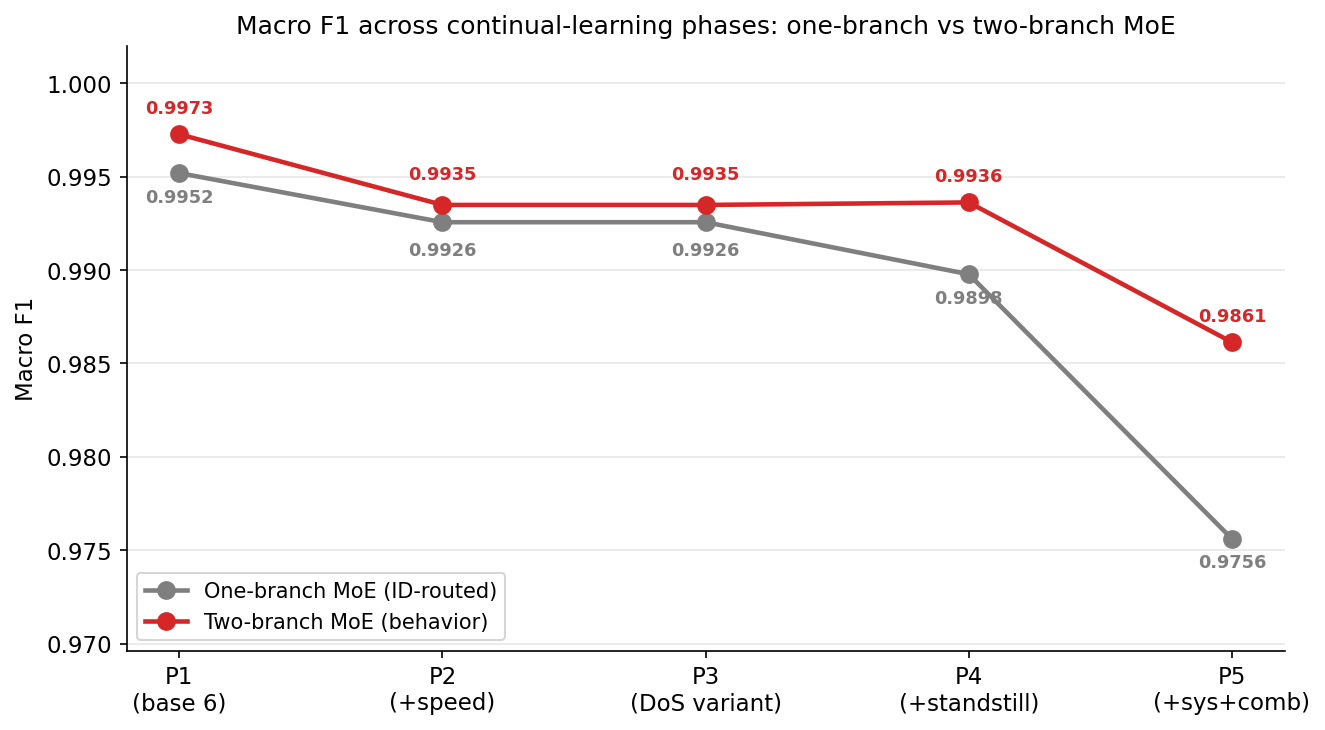

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))

for run in RUNS:
    g = df[df["short"] == run["short"]].sort_values("phase")
    ax.plot(range(len(g)), g["overall_f1"].values,
            marker="o", linewidth=2.2, markersize=8,
            color=COLORS[run["short"]], label=run["name"])

# Annotate with smart offset to avoid overlap
for i in range(5):
    vals = {r["short"]: df[(df["short"]==r["short"]) & (df["phase"]==f"phase{i+1}")]["overall_f1"].values[0] for r in RUNS}
    gap = abs(vals["cosine"] - vals["behavior"])
    # If too close, push apart vertically
    if gap < 0.002:
        upper = max(vals, key=vals.get)
        lower = min(vals, key=vals.get)
        for short, v in vals.items():
            offset = 12 if short == upper else -16
            ax.annotate(f"{v:.4f}", (i, v), textcoords="offset points",
                        xytext=(0, offset), fontsize=8.5, ha="center",
                        color=COLORS[short], fontweight="bold")
    else:
        for short, v in vals.items():
            offset = 10 if v >= max(vals.values()) else -14
            ax.annotate(f"{v:.4f}", (i, v), textcoords="offset points",
                        xytext=(0, offset), fontsize=8.5, ha="center",
                        color=COLORS[short], fontweight="bold")

ax.set_xticks(range(5), PHASE_LABELS)
ax.set_ylabel("Macro F1")
ax.set_title("Macro F1 across continual-learning phases: one-branch vs two-branch MoE", fontsize=12)
ax.legend(loc="lower left", fontsize=10)
ax.set_ylim(bottom=min(df["overall_f1"]) - 0.006, top=1.002)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("compare_f1_phases.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Chart 2: Per-attack F1 at final phase (grouped bars)

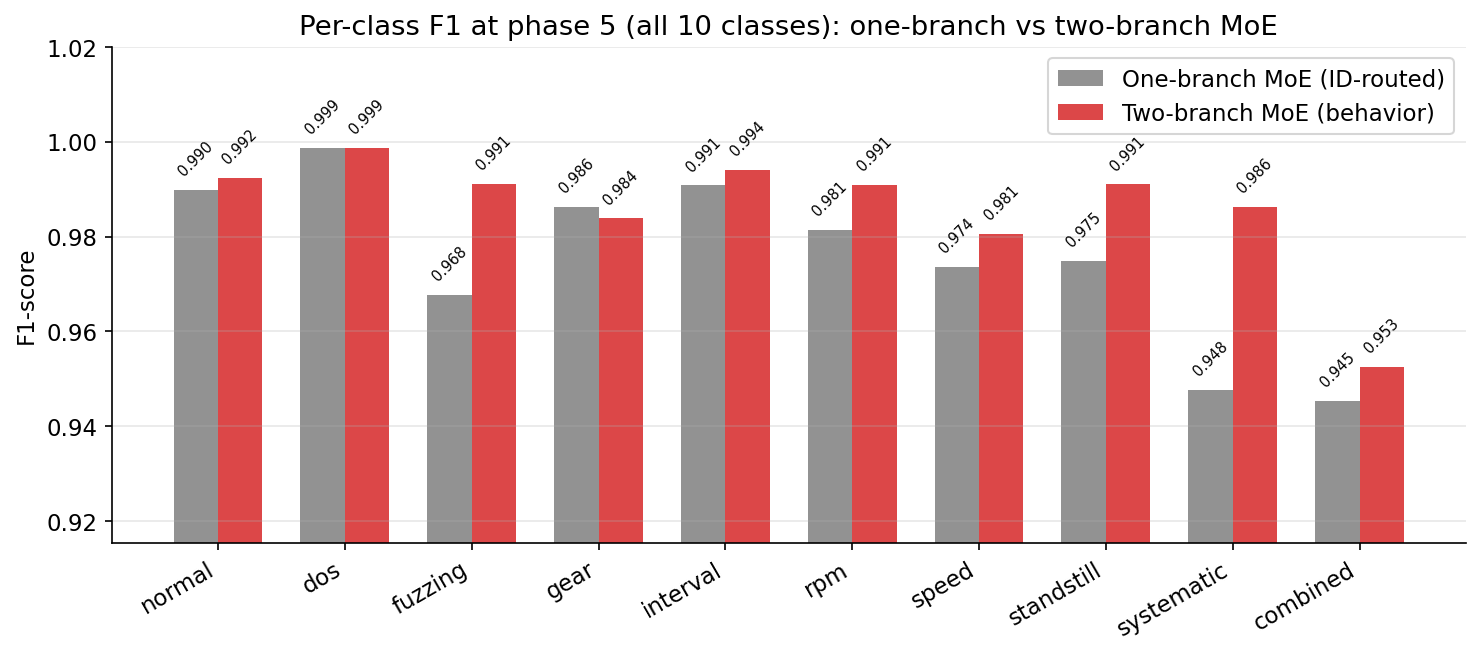

In [8]:
attacks = [c for c in CLASS_NAMES if c in df.columns and df[df["phase"]=="phase5"][c].notna().any()]
final = df[df["phase"] == "phase5"].set_index("short")

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(attacks))
w = 0.35

for i, run in enumerate(RUNS):
    vals = [final.loc[run["short"], a] if a in final.columns else 0 for a in attacks]
    bars = ax.bar(x + i*w - w/2, vals, w, label=run["name"],
                  color=COLORS[run["short"]], alpha=0.85)
    for bar, v in zip(bars, vals):
        if not np.isnan(v):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
                    f"{v:.3f}", ha="center", fontsize=7, rotation=45)

ax.set_xticks(x, attacks, rotation=30, ha="right")
ax.set_ylabel("F1-score")
ax.set_title("Per-class F1 at phase 5 (all 10 classes): one-branch vs two-branch MoE")
ax.legend()
ax.set_ylim(bottom=max(0, final[attacks].min().min() - 0.03), top=1.02)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("compare_per_attack_phase5.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Chart 3: Forgetting analysis

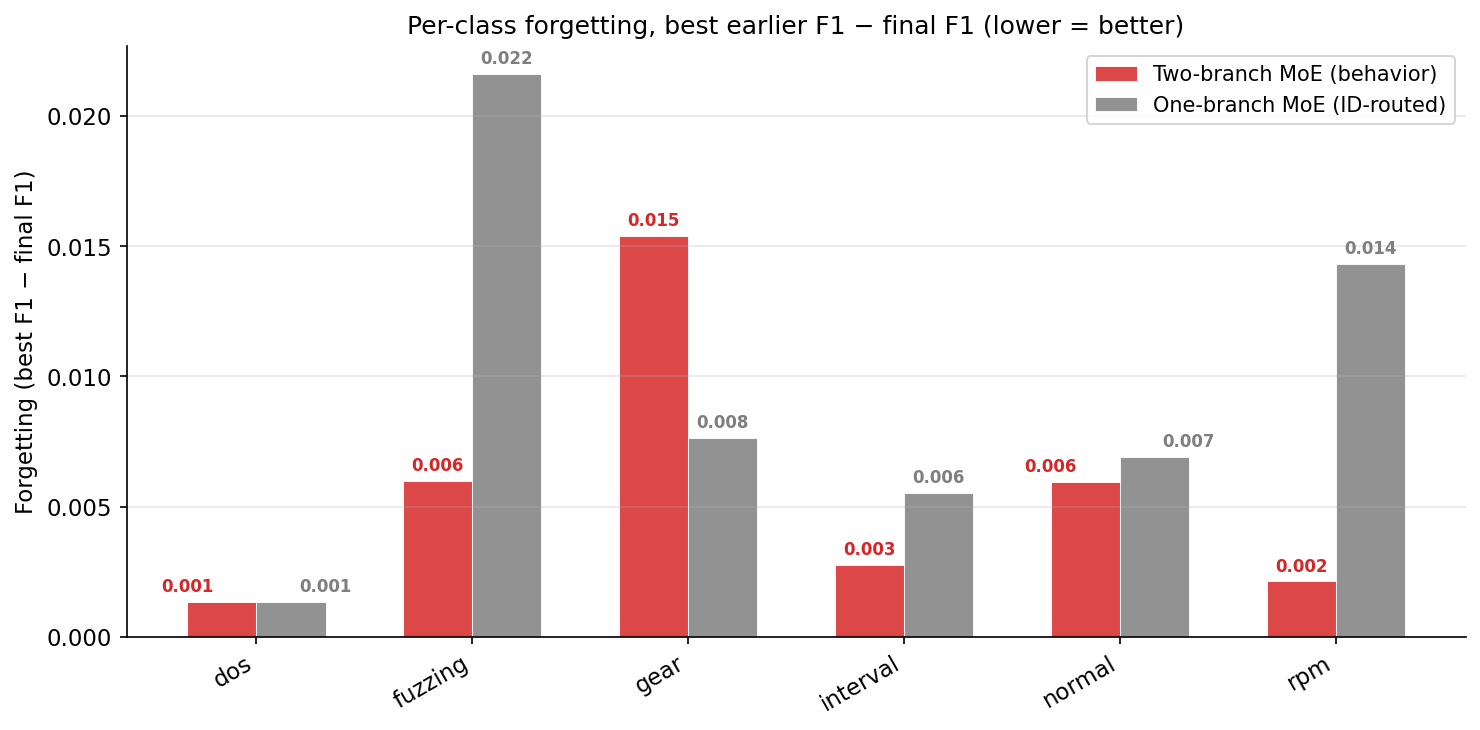


Max forgetting:
  Two-branch MoE (behavior): 0.0154 (gear)
  One-branch MoE (ID-routed): 0.0216 (fuzzing)


In [9]:
def compute_forgetting(df, run_short):
    """Max F1 drop from best to final, per old attack."""
    g = df[df["short"] == run_short].sort_values("phase").reset_index(drop=True)
    # Old attacks = learned before phase5
    old_attacks = [c for c in CLASS_NAMES if c in g.columns
                   and g.iloc[0][c] is not None and not np.isnan(g.iloc[0].get(c, np.nan))]
    forget = {}
    for atk in old_attacks:
        vals = g[atk].dropna().values
        if len(vals) >= 2:
            best = vals[:-1].max()
            final = vals[-1]
            forget[atk] = best - final
    return forget

forget_behavior = compute_forgetting(df, "behavior")
forget_cosine = compute_forgetting(df, "cosine")

# Merge
attacks_common = sorted(set(forget_behavior) & set(forget_cosine))
x = np.arange(len(attacks_common))
w = 0.35

b_vals = [forget_behavior[a] for a in attacks_common]
c_vals = [forget_cosine[a] for a in attacks_common]

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(attacks_common))
w = 0.32

for i, (vals, short) in enumerate([(b_vals, "behavior"), (c_vals, "cosine")]):
    bars = ax.bar(x + i*w - w/2, vals, w, label=NAME[short],
                  color=COLORS[short], alpha=0.85, edgecolor="white", linewidth=0.5)

# Annotate with horizontal offset when bars are close
for i, (bv, cv) in enumerate(zip(b_vals, c_vals)):
    # behavior label
    ha_b, ha_c = "center", "center"
    x_off_b, x_off_c = 0, 0
    if abs(bv - cv) < 0.002 and bv > 0.001:
        ha_b, ha_c = "right", "left"
        x_off_b, x_off_c = -4, 4

    ax.annotate(f"{bv:.3f}", (i - w/2, bv), textcoords="offset points",
                xytext=(x_off_b, 5), fontsize=8, ha=ha_b,
                color=COLORS["behavior"], fontweight="bold")
    ax.annotate(f"{cv:.3f}", (i + w/2, cv), textcoords="offset points",
                xytext=(x_off_c, 5), fontsize=8, ha=ha_c,
                color=COLORS["cosine"], fontweight="bold")

ax.set_xticks(x, attacks_common, rotation=30, ha="right")
ax.set_ylabel("Forgetting (best F1 − final F1)")
ax.set_title("Per-class forgetting, best earlier F1 − final F1 (lower = better)", fontsize=12)
ax.legend(fontsize=10)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("compare_forgetting.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"\nMax forgetting:")
print(f"  {NAME['behavior']}: {max(b_vals):.4f} ({attacks_common[np.argmax(b_vals)]})")
print(f"  {NAME['cosine']}: {max(c_vals):.4f} ({attacks_common[np.argmax(c_vals)]})")

## 6. Per-class trajectory (line chart per attack across phases)

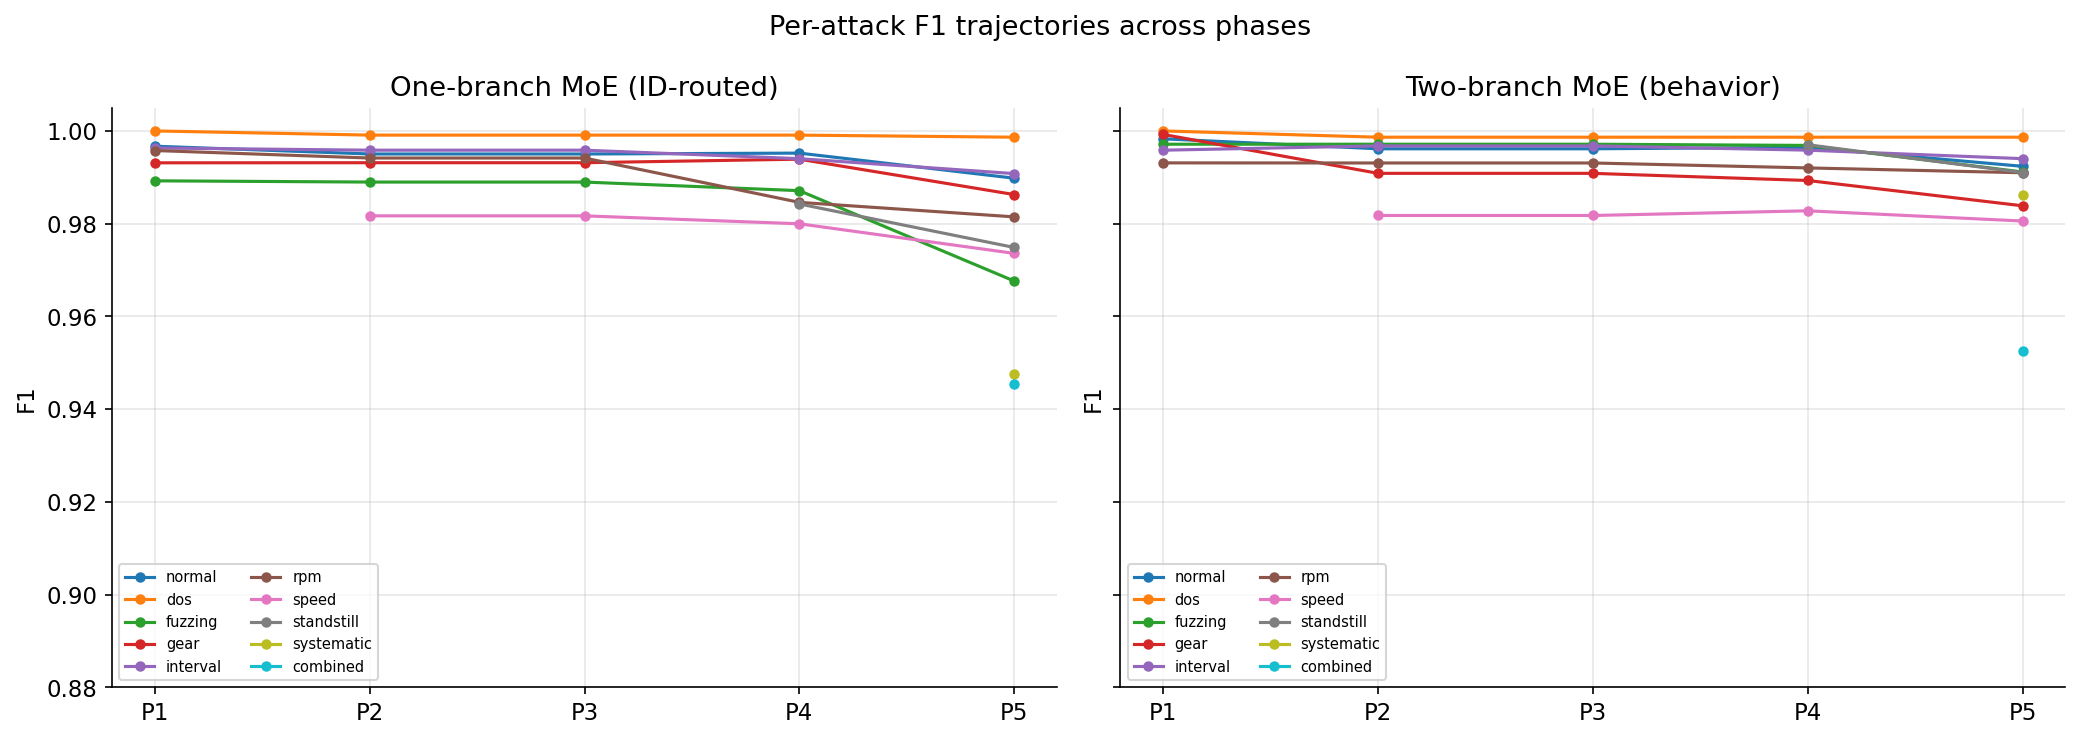

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, run in zip(axes, RUNS):
    g = df[df["short"] == run["short"]].sort_values("phase").reset_index(drop=True)
    cols = [c for c in CLASS_NAMES if c in g.columns and g[c].notna().any()]
    for c in cols:
        vals = g[c].values
        ax.plot(range(len(g)), vals, marker="o", markersize=4, label=c, linewidth=1.5)
    ax.set_xticks(range(len(g)), [f"P{i+1}" for i in range(len(g))])
    ax.set_title(run["name"])
    ax.set_ylabel("F1")
    ax.set_ylim(0.88, 1.005)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, ncol=2, loc="lower left")

fig.suptitle("Per-attack F1 trajectories across phases", fontsize=13)
fig.tight_layout()
fig.savefig("compare_trajectories.png", dpi=200, bbox_inches="tight")
plt.show()

  Loaded 28433 windows from ../data/2011-chevrolet-impala/preprocessed_window/windows_test.pt
  [FastData] packed_test.pt: 28433 graphs, Nmax=46 +behavior +window, 248 MB on GPU


,"NMI(expert, attack class), attacked nodes","NMI(expert, CAN ID), attacked nodes","NMI(expert, CAN ID), benign nodes"
Model,,,
One-branch MoE (ID-routed),0.357,0.308,0.510
Two-branch MoE (behavior),0.437,0.191,0.018


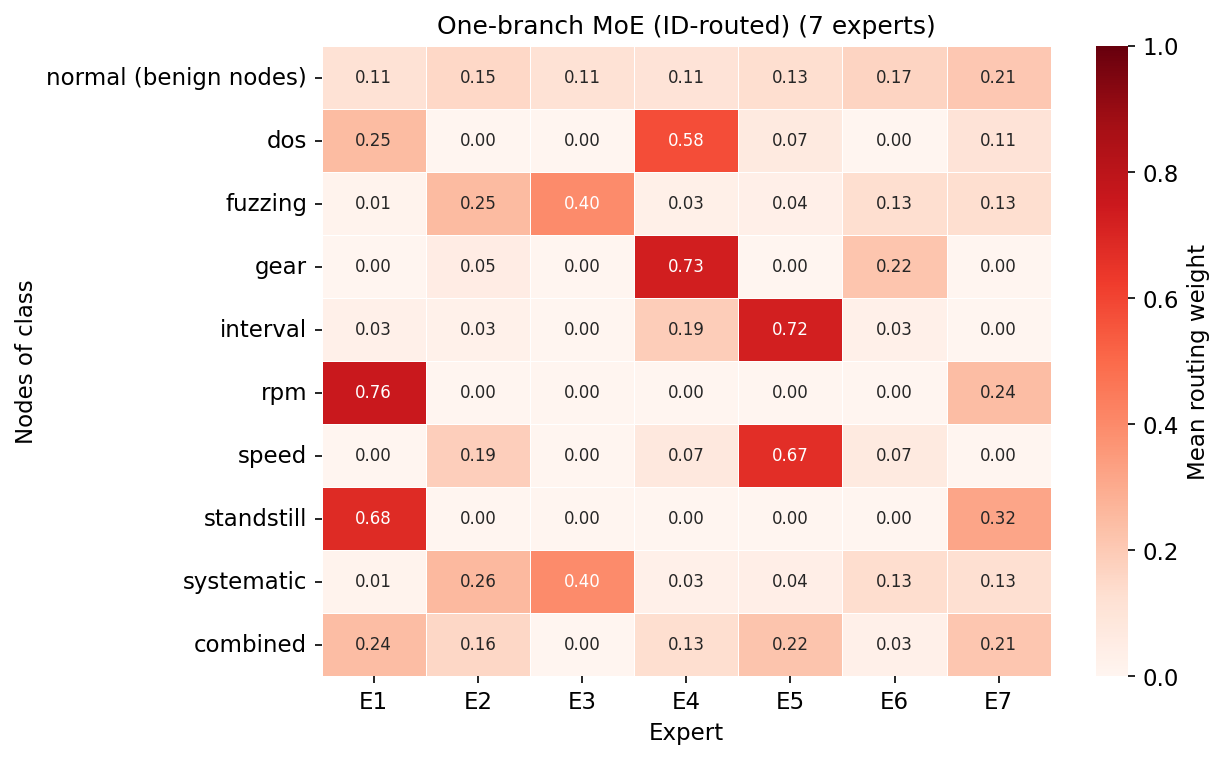

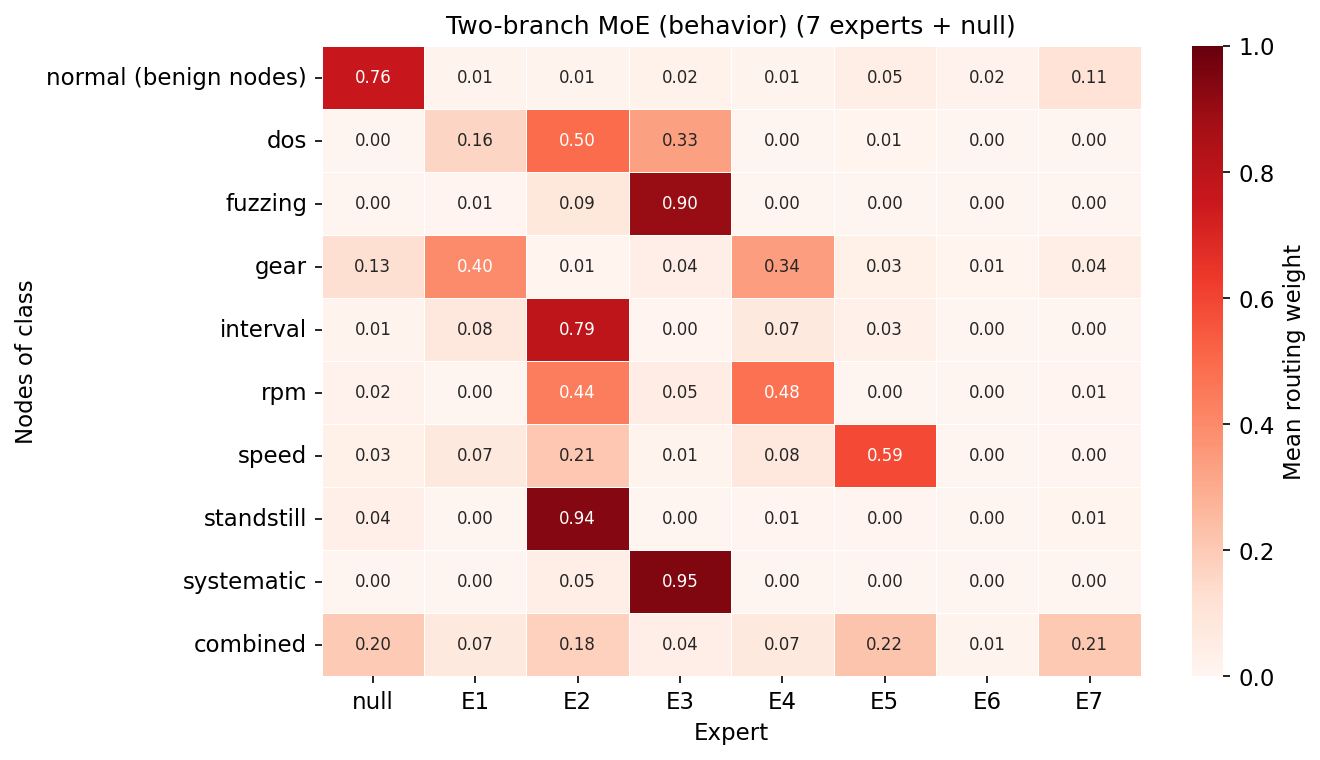

In [11]:
# Route heatmaps for both models, one figure per model.
# Two-branch: routing saved in preds_phase5.npz during training.
# One-branch: routing is recomputed by running the phase-5 checkpoint on the test split
# (forward_padded(..., return_details=True) returns the per-node routing weights).
import seaborn as sns

def last_checkpoint(run_dir):
    for ph in ("phase5", "phase4", "phase3", "phase2", "phase1"):
        p = Path(run_dir) / f"{ph}_best.pth"
        if p.exists():
            return p
    raise FileNotFoundError(run_dir)

def nmi(a, b):
    """Normalised mutual information (arithmetic mean normalisation) of two label arrays."""
    a = np.unique(a, return_inverse=True)[1]; b = np.unique(b, return_inverse=True)[1]
    joint = np.zeros((a.max() + 1, b.max() + 1)); np.add.at(joint, (a, b), 1)
    joint /= joint.sum(); pa, pb = joint.sum(1), joint.sum(0)
    nz = joint > 0
    mi = (joint[nz] * np.log(joint[nz] / (pa[:, None] * pb[None, :])[nz])).sum()
    ha, hb = -(pa[pa > 0] * np.log(pa[pa > 0])).sum(), -(pb[pb > 0] * np.log(pb[pb > 0])).sum()
    return float(2 * mi / (ha + hb)) if ha + hb > 0 else 0.0

@torch.no_grad()
def node_routing_one_branch(run):
    """Per-node routing weights, attack flag, class and CAN-ID index for the one-branch model."""
    ck = torch.load(last_checkpoint(run["dir"]), map_location="cpu", weights_only=False)
    sd = ck["model"] if "model" in ck else ck
    args0 = ck.get("args", {})
    model = build_from_state(sd, run["arch"], args0).to(DEVICE).eval()
    loader = get_phase_plan(run["data_dir"])[-1]["loader"]          # phase-5 test set
    W, A, Y, I = [], [], [], []
    for batch in loader:
        out = model.forward_padded(batch["x"], batch["ids"], batch["adj"], batch["n"],
                                   return_details=True)
        n = batch["n"]
        mask = torch.arange(batch["x"].size(1), device=n.device)[None, :] < n[:, None]
        W.append(torch.cat(out["routing_weights"]).float().cpu())
        A.append(batch["node_atk"][mask].float().cpu())
        Y.append(batch["y"].repeat_interleave(n).cpu())
        I.append(batch["ids"][mask].cpu())
    del model; torch.cuda.empty_cache()
    return {"probs": torch.cat(W).numpy(), "atk": torch.cat(A).numpy(),
            "ny": torch.cat(Y).numpy(), "ids": torch.cat(I).numpy()}

def node_routing_two_branch(run):
    z = np.load(Path(run["dir"]) / "preds_phase5.npz")
    return {"probs": z["node_probs"].astype(np.float32), "atk": z["node_atk"],
            "ny": z["node_ny"], "ids": z["node_ids"]}

def routing_matrix(nd, min_nodes=20):
    atk, ny, pr = nd["atk"] > 0, nd["ny"], nd["probs"]
    rows, labels = [pr[~atk].mean(0)], ["normal (benign nodes)"]
    for c in range(1, len(CLASS_NAMES)):
        sel = atk & (ny == c)
        if sel.sum() >= min_nodes:
            rows.append(pr[sel].mean(0)); labels.append(CLASS_NAMES[c])
    return np.vstack(rows), labels

# ---------- Compute routing for every run ----------
ROUTING, NMI_ROWS = {}, []
for run in RUNS:
    nd = node_routing_one_branch(run) if run["arch"] == "cosine" else node_routing_two_branch(run)
    ROUTING[run["short"]] = nd
    atk = nd["atk"] > 0
    top = nd["probs"].argmax(1)
    if run["arch"] != "cosine":          # two-branch: ignore the null column for "active expert"
        top = nd["probs"][:, 1:].argmax(1)
    NMI_ROWS.append({"Model": run["name"],
                     "NMI(expert, attack class), attacked nodes": nmi(top[atk], nd["ny"][atk]),
                     "NMI(expert, CAN ID), attacked nodes": nmi(top[atk], nd["ids"][atk]),
                     "NMI(expert, CAN ID), benign nodes": nmi(top[~atk], nd["ids"][~atk])})
display(pd.DataFrame(NMI_ROWS).set_index("Model").round(3))

# ---------- One figure per model, saved separately ----------
for run in RUNS:
    M, labels = routing_matrix(ROUTING[run["short"]])
    is_one_branch = run["arch"] == "cosine"
    xt = ([f"E{i}" for i in range(1, M.shape[1] + 1)] if is_one_branch
          else ["null"] + [f"E{i}" for i in range(1, M.shape[1])])
    n_experts = len(xt) - (0 if is_one_branch else 1)

    fig, ax = plt.subplots(figsize=(0.75 * M.shape[1] + 3.2, 5.2))
    sns.heatmap(M, ax=ax, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1,
                xticklabels=xt, yticklabels=labels,
                cbar_kws={"label": "Mean routing weight"},
                annot_kws={"fontsize": 8}, linewidths=0.4, linecolor="white")
    ax.set_title(f"{run['name']} ({n_experts} experts"
                 f"{'' if is_one_branch else ' + null'})", fontsize=12)
    ax.set_xlabel("Expert")
    ax.set_ylabel("Nodes of class")
    ax.tick_params(axis="y", rotation=0)

    fig.tight_layout()
    fig.savefig(f"route_heatmap_{run['short']}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 7. Summary table for slides

In [24]:
summary_rows = []
for run in RUNS:
    g = df[df["short"] == run["short"]].sort_values("phase").reset_index(drop=True)
    last = g.iloc[-1]
    forget = compute_forgetting(df, run["short"])
    max_f = max(forget.values()) if forget else 0
    max_f_cls = max(forget, key=forget.get) if forget else ""

    # New attack F1 when first learned
    new_f1s = []
    for i, row in g.iterrows():
        if row["type"] in ("new",) and i > 0:
            for c in row["_new_classes"]:
                if c in row and not np.isnan(row[c]):
                    new_f1s.append(row[c])

    summary_rows.append({
        "Method": run["name"],
        "Phase 5 F1": f"{last['overall_f1']:.4f}",
        "Max forget": f"{max_f:.4f} ({max_f_cls})",
        "New attack F1 (avg)": f"{np.mean(new_f1s):.4f}" if new_f1s else "N/A",
        "Normal FPR": f"{last['normal_fpr']:.4f}",
        "Experts": last["experts"],
    })

summary = pd.DataFrame(summary_rows).set_index("Method")
display(summary)
summary.to_csv("comparison_summary.csv")
print("Saved: comparison_summary.csv")

,Phase 5 F1,Max forget,New attack F1 (avg),Normal FPR,Experts
Method,,,,,
One-branch MoE (ID-routed),0.9756,0.0216 (fuzzing),0.9647,0.0068,7
Two-branch MoE (behavior),0.9861,0.0154 (gear),0.9794,0.0064,7


Saved: comparison_summary.csv


## 8. Export all per-phase per-attack data (for LaTeX tables)

In [ ]:
# Full data export
export_cols = ["run", "phase", "type", "experts", "overall_f1", "acc", "normal_fpr"] + \
              [c for c in CLASS_NAMES if c in df.columns]
export = df[[c for c in export_cols if c in df.columns]].copy()
display(export.round(4))
export.to_csv("comparison_full.csv", index=False)
print("Saved: comparison_full.csv")